# 03 · Análisis: tres hallazgos sobre la exposición del Perú al EUDR

**Pregunta:** ¿cuánto exporta el Perú a la Unión Europea en café, cacao y madera, a qué países, y qué tan expuesto está cada producto
al Reglamento (UE) 2023/1115 (EUDR), que se aplicará desde el 30 de diciembre de 2026?

Este notebook usa las tablas procesadas del notebook 02, calcula las cifras de los hallazgos y guarda:
- los gráficos en `figuras/` (sirven para el README y el reel),
- los textos de los hallazgos en `web/data/hallazgos.json`, que el dashboard lee. Así las cifras del tablero salen de este cálculo.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import MaxNLocator

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESADOS = RAIZ / "datos" / "procesados"
FIGURAS = RAIZ / "figuras"
FIGURAS.mkdir(exist_ok=True)

mensual = pd.read_csv(PROCESADOS / "exportaciones_eudr_mensual.csv", dtype={"subpartida": str})
ind = pd.read_csv(PROCESADOS / "indicadores_anuales_producto.csv")
total_ue = pd.read_csv(PROCESADOS / "total_exportado_ue27_anual.csv", index_col="anio")

ANIO_PARCIAL = int(mensual.anio.max())
ULTIMO_MES = int(mensual.loc[mensual.anio == ANIO_PARCIAL, "mes"].max())
ULTIMO = ANIO_PARCIAL - 1  # último año completo
MESES = ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto", "setiembre", "octubre", "noviembre", "diciembre"]
PERIODO = f"enero–{MESES[ULTIMO_MES - 1]}"

anual = ind.query("periodo == 'anual'").set_index(["producto", "anio"])
comparable = ind.query("periodo == 'comparable'").set_index(["producto", "anio"])

COLORES = {"Café": "#eb6834", "Cacao": "#2a78d6", "Madera": "#1baf7a"}
UE, RESTO, TINTA, TINTA2, REJILLA = "#2a78d6", "#a3a19a", "#0b0b0b", "#52514e", "#e1e0d9"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 10.5, "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TINTA2,
    "xtick.color": TINTA2, "ytick.color": TINTA2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": REJILLA, "grid.linewidth": 0.8, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left", "legend.frameon": False,
})


def millones(x: float) -> str:
    return f"US$ {x / 1e6:,.0f} millones" if x >= 1e8 else f"US$ {x / 1e6:,.1f} millones"


def miles_t(kg: float) -> str:
    return f"{kg / 1e6:,.1f} mil toneladas"

## Panorama: valor FOB exportado a la UE-27 por producto

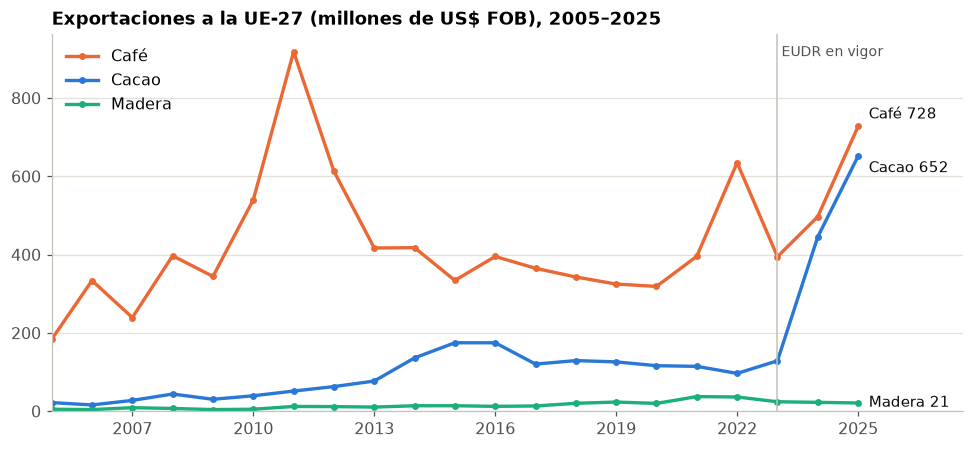

producto,Cacao,Café,Madera
anio,,,
2020,116.4,318.8,20.1
2021,114.7,395.8,37.5
2022,96.7,634.9,36.5
2023,128.9,395.0,24.3
2024,445.4,497.1,22.8
2025,651.6,727.5,21.1


In [2]:
tabla = anual.reset_index().pivot(index="anio", columns="producto", values="fob_ue") / 1e6
fig, ax = plt.subplots(figsize=(9, 4.2))
desplazamiento = {"Café": 8, "Cacao": -8, "Madera": 0}
for prod, color in COLORES.items():
    ax.plot(tabla.index, tabla[prod], color=color, lw=2.2, marker="o", ms=3.5, label=prod)
    ax.annotate(f"{prod} {tabla[prod].iloc[-1]:,.0f}", (tabla.index[-1], tabla[prod].iloc[-1]), xytext=(7, desplazamiento[prod]),
                textcoords="offset points", va="center", color=TINTA, fontsize=9.5)
ax.axvline(2023, color="#c3c2b7", lw=1)
ax.text(2023.1, ax.get_ylim()[1] * 0.97, "EUDR en vigor", color=TINTA2, fontsize=9, va="top")
ax.set_title(f"Exportaciones a la UE-27 (millones de US$ FOB), 2005–{ULTIMO}")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlim(2005, ULTIMO + 2.6)
ax.set_ylim(0)
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIGURAS / "01_fob_ue_por_producto.png")
plt.show()
tabla.tail(6).round(1)

## Hallazgo 1 · Cerca de US$ 1 400 millones de exportaciones peruanas quedarán bajo las reglas del EUDR

In [3]:
fob_ue_ult = {p: anual.loc[(p, ULTIMO), "fob_ue"] for p in COLORES}
total_eudr_ue = sum(fob_ue_ult.values())
part_ue_ult = {p: anual.loc[(p, ULTIMO), "part_ue_fob"] for p in COLORES}
peso_en_ue = mensual[mensual.ue27].groupby("anio").fob_usd.sum() / total_ue.fob_total_ue * 100
anio_base = 2023

h1 = {
    "titulo": f"La UE compra el {part_ue_ult['Café']:.0f} % del café y el {part_ue_ult['Cacao']:.0f} % del cacao peruano",
    "texto": (
        f"En {ULTIMO}, el Perú envió a la UE-27 <strong>{millones(total_eudr_ue)}</strong> en productos que regula el EUDR: "
        f"café ({millones(fob_ue_ult['Café'])}), cacao ({millones(fob_ue_ult['Cacao'])}) y madera ({millones(fob_ue_ult['Madera'])}). "
        f"Estos productos ya son el <strong>{peso_en_ue[ULTIMO]:.1f} %</strong> de todo lo que el Perú vende a la UE "
        f"({peso_en_ue[anio_base]:.1f} % en {anio_base}). Desde el 30/12/2026, cada uno de esos envíos necesitará una declaración "
        "de diligencia debida con la geolocalización de las parcelas."
    ),
}
print(h1["titulo"])
print(h1["texto"])
peso_en_ue.tail(8).round(1).rename("% del total exportado a la UE")

La UE compra el 40 % del café y el 40 % del cacao peruano
En 2025, el Perú envió a la UE-27 <strong>US$ 1,400 millones</strong> en productos que regula el EUDR: café (US$ 728 millones), cacao (US$ 652 millones) y madera (US$ 21.1 millones). Estos productos ya son el <strong>13.7 %</strong> de todo lo que el Perú vende a la UE (7.9 % en 2023). Desde el 30/12/2026, cada uno de esos envíos necesitará una declaración de diligencia debida con la geolocalización de las parcelas.


anio
2019     8.3
2020     8.8
2021     7.5
2022    11.4
2023     7.9
2024    11.7
2025    13.7
2026     7.8
Name: % del total exportado a la UE, dtype: float64

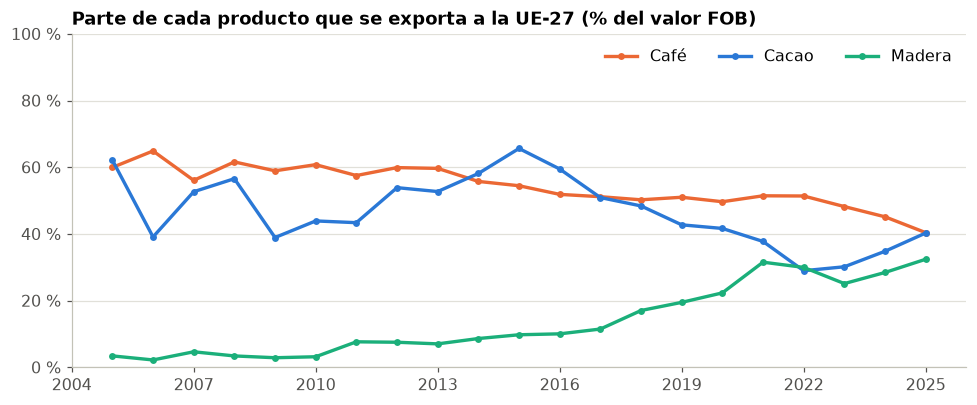

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.8))
part = anual.reset_index().pivot(index="anio", columns="producto", values="part_ue_fob")
for prod, color in COLORES.items():
    ax.plot(part.index, part[prod], color=color, lw=2.2, marker="o", ms=3.5, label=prod)
ax.set_ylim(0, 100)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_title("Parte de cada producto que se exporta a la UE-27 (% del valor FOB)")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f} %")
ax.legend(loc="upper right", ncols=3)
fig.tight_layout()
fig.savefig(FIGURAS / "02_participacion_ue.png")
plt.show()

## Hallazgo 2 · El salto del cacao hacia la UE fue sobre todo de precio, y es cacao en grano

In [5]:
c23, c25 = anual.loc[("Cacao", 2023)], anual.loc[("Cacao", ULTIMO)]
sub_cacao = (
    mensual[(mensual.anio == ULTIMO) & (mensual.producto == "Cacao")]
    .groupby(["ue27", "subgrupo"]).fob_usd.sum()
)
sub_ue, sub_resto = sub_cacao.xs(True, level="ue27"), sub_cacao.xs(False, level="ue27")
grano_ue = sub_ue["Cacao en grano"] / sub_ue.sum() * 100
grano_resto = sub_resto["Cacao en grano"] / sub_resto.sum() * 100
cp_act, cp_prev = comparable.loc[("Cacao", ANIO_PARCIAL)], comparable.loc[("Cacao", ULTIMO)]

h2 = {
    "titulo": f"El cacao vendido a la UE se multiplicó por {c25.fob_ue / c23.fob_ue:.0f} en dos años, sobre todo por precio",
    "texto": (
        f"Entre 2023 y {ULTIMO}, el cacao exportado a la UE pasó de {millones(c23.fob_ue)} a <strong>{millones(c25.fob_ue)}</strong>. "
        f"El volumen solo se multiplicó por {c25.kg_ue / c23.kg_ue:.1f} ({miles_t(c23.kg_ue)} → {miles_t(c25.kg_ue)}), "
        f"porque el valor unitario subió de {c23.vu_ue:.2f} a {c25.vu_ue:.2f} US$/kg. "
        f"El <strong>{grano_ue:.0f} %</strong> de lo que va a la UE es cacao en grano (contra {grano_resto:.0f} % al resto del mundo), "
        f"la materia prima que el EUDR exige rastrear hasta la parcela. En {PERIODO} de {ANIO_PARCIAL}, con precios más bajos, "
        f"el valor enviado a la UE cayó {abs(cp_act.var_fob_ue):.0f} % y el volumen {abs(cp_act.var_kg_ue):.0f} %."
    ),
}
print(h2["titulo"])
print(h2["texto"])

El cacao vendido a la UE se multiplicó por 5 en dos años, sobre todo por precio
Entre 2023 y 2025, el cacao exportado a la UE pasó de US$ 129 millones a <strong>US$ 652 millones</strong>. El volumen solo se multiplicó por 2.1 (34.2 mil toneladas → 73.5 mil toneladas), porque el valor unitario subió de 3.77 a 8.87 US$/kg. El <strong>77 %</strong> de lo que va a la UE es cacao en grano (contra 48 % al resto del mundo), la materia prima que el EUDR exige rastrear hasta la parcela. En enero–agosto de 2026, con precios más bajos, el valor enviado a la UE cayó 56 % y el volumen 15 %.


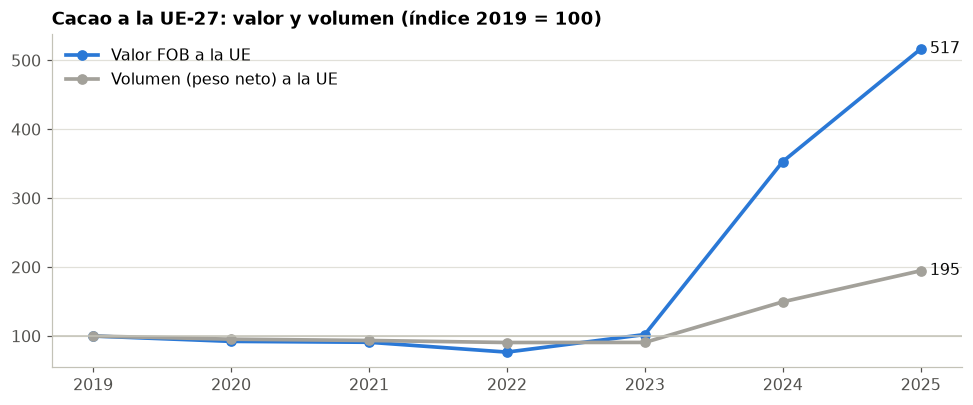

,Valor FOB a la UE,Volumen a la UE
anio,,
2019,100.0,100.0
2020,92.0,95.0
2021,91.0,94.0
2022,77.0,91.0
2023,102.0,91.0
2024,353.0,150.0
2025,517.0,195.0


In [6]:
base = anual.loc["Cacao"].loc[2019:ULTIMO]
indice = pd.DataFrame({
    "Valor FOB a la UE": base.fob_ue / base.fob_ue.loc[2019] * 100,
    "Volumen a la UE": base.kg_ue / base.kg_ue.loc[2019] * 100,
})
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(indice.index, indice["Valor FOB a la UE"], color=COLORES["Cacao"], lw=2.4, marker="o", label="Valor FOB a la UE")
ax.plot(indice.index, indice["Volumen a la UE"], color=RESTO, lw=2.4, marker="o", label="Volumen (peso neto) a la UE")
for col in indice:
    ax.annotate(f"{indice[col].iloc[-1]:.0f}", (indice.index[-1], indice[col].iloc[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", color=TINTA)
ax.axhline(100, color="#c3c2b7", lw=1)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_title("Cacao a la UE-27: valor y volumen (índice 2019 = 100)")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIGURAS / "03_cacao_valor_vs_volumen.png")
plt.show()
indice.round(0)

## Hallazgo 3 · El café peruano depende menos de la UE: el volumen enviado a Europa cae mientras el total se mantiene

In [7]:
f19, f25 = anual.loc[("Café", 2019)], anual.loc[("Café", ULTIMO)]
cafe_paises = mensual[(mensual.anio == ULTIMO) & (mensual.producto == "Café")].groupby("pais").fob_usd.sum().sort_values(ascending=False)
cafe_ue = mensual[(mensual.anio == ULTIMO) & (mensual.producto == "Café") & mensual.ue27].groupby("pais").fob_usd.sum()
top2_ue = cafe_ue.sort_values(ascending=False).head(2)
part_top2 = top2_ue.sum() / cafe_ue.sum() * 100
pico_part = anual.loc["Café"].part_ue_fob.loc[2015:ULTIMO]

h3 = {
    "titulo": (
        f"El café se aleja de Europa: la UE pasó de {pico_part.max():.0f} % ({pico_part.idxmax()}) "
        f"a {f25.part_ue_fob:.0f} % ({ULTIMO}) de las ventas"
    ),
    "texto": (
        f"Entre 2019 y {ULTIMO}, el volumen de café enviado a la UE cayó {abs(f25.kg_ue / f19.kg_ue - 1) * 100:.0f} % "
        f"({miles_t(f19.kg_ue)} → {miles_t(f25.kg_ue)}), mientras el total exportado subió {(f25.kg_total / f19.kg_total - 1) * 100:.0f} %. "
        f"Estados Unidos es hoy el primer comprador individual ({cafe_paises.iloc[0] / cafe_paises.sum() * 100:.0f} % del valor). "
        f"Dentro de la UE, la demanda está muy concentrada: {top2_ue.index[0]} y {top2_ue.index[1]} reciben el "
        f"<strong>{part_top2:.0f} %</strong> del café peruano que entra al bloque. "
        "El cambio coincide con la llegada del EUDR, pero los datos de comercio no permiten atribuírselo solo a él: también influyen "
        "los precios y la demanda de cada mercado."
    ),
}
print(h3["titulo"])
print(h3["texto"])

El café se aleja de Europa: la UE pasó de 54 % (2015) a 40 % (2025) de las ventas
Entre 2019 y 2025, el volumen de café enviado a la UE cayó 18 % (117.3 mil toneladas → 95.9 mil toneladas), mientras el total exportado subió 4 %. Estados Unidos es hoy el primer comprador individual (33 % del valor). Dentro de la UE, la demanda está muy concentrada: Alemania y Bélgica reciben el <strong>67 %</strong> del café peruano que entra al bloque. El cambio coincide con la llegada del EUDR, pero los datos de comercio no permiten atribuírselo solo a él: también influyen los precios y la demanda de cada mercado.


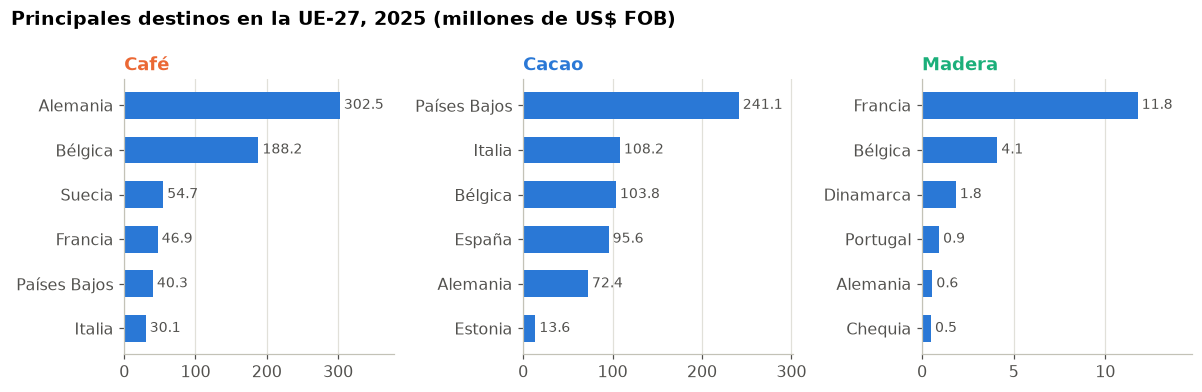

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), sharex=False)
for ax, prod in zip(axes, COLORES):
    serie = (
        mensual[(mensual.anio == ULTIMO) & (mensual.producto == prod) & mensual.ue27]
        .groupby("pais").fob_usd.sum().sort_values().tail(6) / 1e6
    )
    ax.barh(serie.index, serie.values, color=UE, height=0.6)
    for y, v in enumerate(serie.values):
        ax.text(v, y, f" {v:,.1f}", va="center", fontsize=9, color=TINTA2)
    ax.set_title(prod, color=COLORES[prod])
    ax.set_axisbelow(True)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    ax.set_xlim(0, serie.max() * 1.25)
fig.suptitle(f"Principales destinos en la UE-27, {ULTIMO} (millones de US$ FOB)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURAS / "04_destinos_ue.png")
plt.show()

## Nota sobre la madera

La madera es el producto EUDR más pequeño y el que más cae. La participación de la UE crece porque Francia compra madera perfilada
(pisos y *decking*) de mayor valor unitario, mientras se desploman las ventas de madera aserrada a China y México.

In [9]:
m15, m25 = anual.loc[("Madera", 2015)], anual.loc[("Madera", ULTIMO)]
print(f"Madera, total exportado: {millones(m15.fob_total)} (2015) → {millones(m25.fob_total)} ({ULTIMO})")
print(f"Participación UE: {m15.part_ue_fob:.1f} % → {m25.part_ue_fob:.1f} %")
print(f"Valor unitario UE vs resto ({ULTIMO}): {m25.vu_ue:.2f} vs {m25.vu_resto:.2f} US$/kg")

Madera, total exportado: US$ 145 millones (2015) → US$ 65.2 millones (2025)
Participación UE: 9.7 % → 32.4 %
Valor unitario UE vs resto (2025): 1.51 vs 0.82 US$/kg


## Guardar hallazgos para el dashboard

In [10]:
hallazgos = [h1, h2, h3]
ruta = RAIZ / "web" / "data" / "hallazgos.json"
ruta.write_text(json.dumps(hallazgos, ensure_ascii=False, indent=2), encoding="utf-8")
print("Guardado:", ruta.relative_to(RAIZ))
for f in sorted(FIGURAS.glob("*.png")):
    print("Figura:", f.relative_to(RAIZ))

Guardado: web\data\hallazgos.json
Figura: figuras\01_fob_ue_por_producto.png
Figura: figuras\02_participacion_ue.png
Figura: figuras\03_cacao_valor_vs_volumen.png
Figura: figuras\04_destinos_ue.png


## Limitaciones

- **Destino declarado ≠ consumo final.** Bélgica y Países Bajos son puertos de entrada (Amberes, Róterdam). Parte de lo que llega ahí
  se reexporta dentro o fuera de la UE.
- **Alcance parcial del EUDR.** No se incluyen pulpa y papel (capítulos 47–49) ni muebles de madera (9401/9403).
- **Año parcial.** Para 2026 solo hay datos de enero a agosto. Las comparaciones usan el mismo periodo del año anterior.
- **Comercio no es deforestación.** Los datos no dicen qué envíos cumplirían el EUDR ni de qué parcelas provienen.
- **Causalidad.** Las variaciones coinciden en el tiempo con el EUDR, pero también responden a precios internacionales (el cacao llegó
  a máximos históricos en 2024), al clima y a la demanda.